# 04 · Model Explainability

A maintenance engineer will not ground an engine because "the model said so". This notebook opens the production models with **SHAP**:

1. Global drivers of the RUL prediction, by feature and by physical component.
2. How the drivers **change over the life** of an engine.
3. Local explanations of individual high-risk predictions.
4. What separates high-risk engines from healthy ones.
5. Which base learners of the stacking ensemble drive a given prediction.

**Exact SHAP for a stacking ensemble.** SHAP values are additive over a linear combination of models. With a non-negative Ridge meta-learner, `f(x) = b + Σ wᵢ fᵢ(x)`, so `φ(f) = Σ wᵢ φ(fᵢ)`. Each tree ensemble is explained exactly with TreeSHAP and the Ridge base learner in closed form (`src/models/predict.py::StackedShapExplainer`). Contributions add up exactly to the model output.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from src.utils import load_config
from src.utils import visualization as viz
from src.data.load_data import load_dataset, SENSOR_DESCRIPTIONS
from src.data.preprocess import add_train_rul, add_test_rul, split_engines, last_cycle_rows
from src.features.engineering import describe_feature
from src.models.predict import load_predictor

cfg = load_config(ROOT / "config.yaml")
viz.set_style()
FIG = ROOT / cfg["paths"]["figures_dir"]
SEED, MAX_RUL = cfg["project"]["random_seed"], cfg["target"]["max_rul"]

NAME = "FD001"
bundle = load_predictor(NAME, ROOT / "models")
ds = load_dataset(NAME, ROOT / cfg["paths"]["raw_dir"])
test = add_test_rul(ds.test, ds.test_rul, MAX_RUL)
F_test = bundle.compute_features(ds.test)
X_last = F_test.loc[F_test.groupby("unit")["cycle"].idxmax()]
pred = bundle.predict_from_features(X_last).set_index("unit")
pred["rul_true"] = test.loc[last_cycle_rows(test).index].set_index("unit")["rul"]
explainer = bundle.explainer()
exp = explainer.explanation(bundle.model_inputs(X_last))
exp.feature_names = [describe_feature(f) for f in explainer.feature_names]
print(f"Model: {bundle.model_name} · {len(explainer.feature_names)} input features · base value {explainer.expected_value:.1f} cycles")
gap = np.abs(exp.base_values + exp.values.sum(1) - bundle.model_pipeline[-1].predict(bundle.model_inputs(X_last))).max()
print(f"Local accuracy check (max |base + Σφ − f(x)|): {gap:.2e} cycles")

00:39:30 | INFO    | src.data.load_data | Loaded FD001: 100 train engines (20631 rows), 100 test engines (13096 rows)


Model: stacking · 120 input features · base value 87.0 cycles
Local accuracy check (max |base + Σφ − f(x)|): 1.56e-13 cycles


## 1. Global explanation

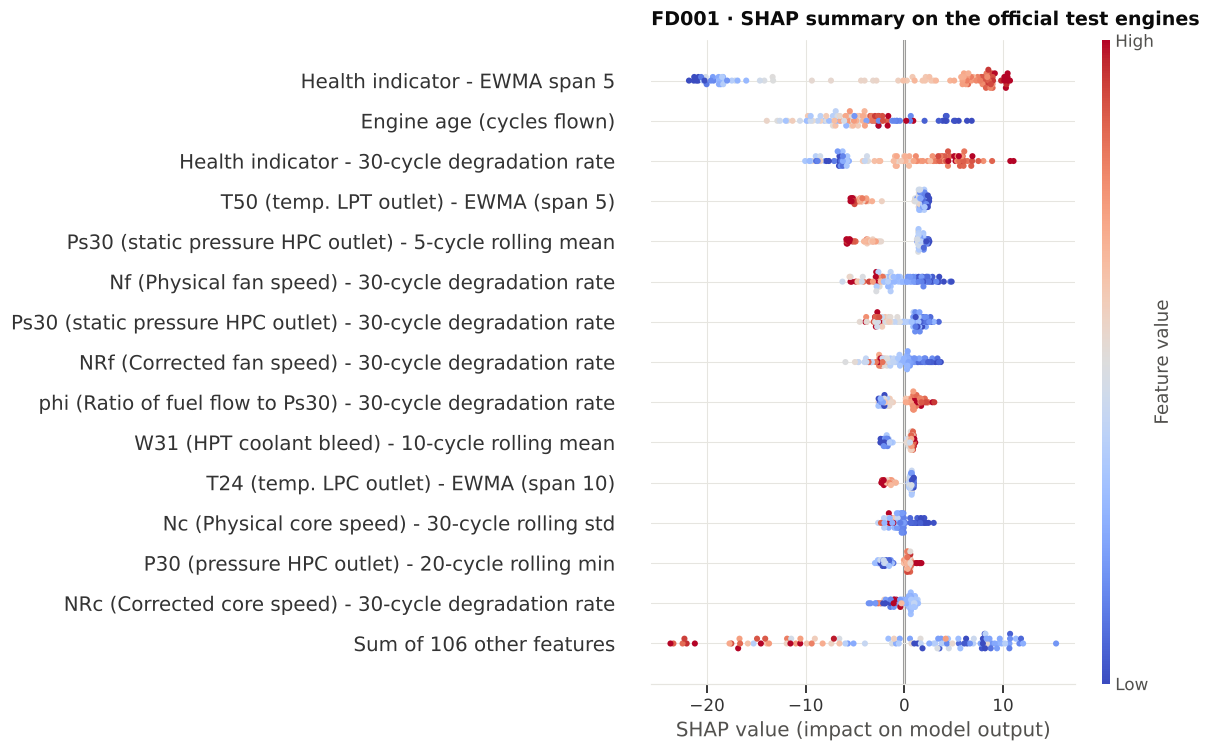

In [2]:
plt.figure()
shap.plots.beeswarm(exp, max_display=15, show=False, plot_size=(11, 7), color=plt.get_cmap("coolwarm"))
plt.title(f"{NAME} · SHAP summary on the official test engines", loc="left", fontweight="bold")
plt.tight_layout(); viz.save_figure(plt.gcf(), f"{NAME}_shap_beeswarm", FIG); plt.show()

* The fused **health indicator** dominates: a low HI (blue) removes up to ~22 cycles from the prediction, a high HI adds up to ~11.
* **Engine age** (cycles flown) is the second driver: older engines (red) receive a lower RUL. Fleet lifetimes are bounded, so age is a legitimate prior that complements the sensors.
* **Degradation-rate features (30-cycle slopes)** of the HI, Ps30 and the fan speeds follow: the model looks not only at *where* the engine is but at *how fast it is moving*.
* The "106 other features" row is wide: beyond the top-15, many small contributions add up, a sign that the prediction rests on a broad, redundant evidence base rather than on one fragile feature.

### Importance aggregated by physical sensor

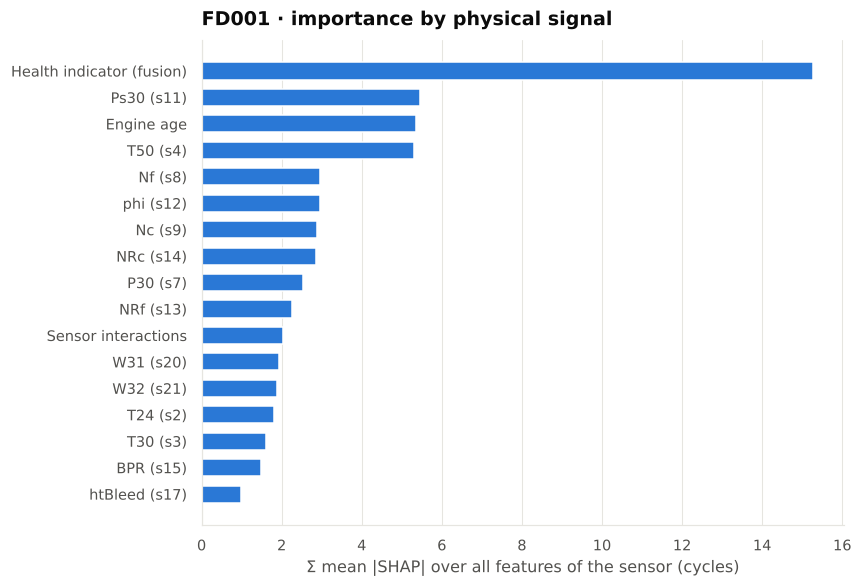

In [3]:
raw_names = explainer.feature_names
abs_mean = pd.Series(np.abs(exp.values).mean(0), index=raw_names)
def owner(f):
    if f.startswith("health_indicator"): return "Health indicator (fusion)"
    if f == "cycle": return "Engine age"
    if f.startswith("ix_"): return "Sensor interactions"
    s = f.split("_")[0]
    return SENSOR_DESCRIPTIONS[s].split(" - ")[0] + f" ({s})" if s in SENSOR_DESCRIPTIONS else f
by_sensor = abs_mean.groupby([owner(f) for f in raw_names]).sum().sort_values()
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(by_sensor.index, by_sensor.values, color=viz.PALETTE[0], height=0.65)
ax.set(xlabel="Σ mean |SHAP| over all features of the sensor (cycles)", title=f"{NAME} · importance by physical signal")
ax.grid(axis="y", visible=False); fig.tight_layout(); viz.save_figure(fig, f"{NAME}_shap_by_sensor", FIG); plt.show()

Beyond the fused indicator, the HPC-outlet static pressure (**Ps30**) and the LPT outlet temperature (**T50**) lead, followed by fan / core speeds and the fuel-flow ratio (**phi**). This is the textbook signature of HPC efficiency loss: the compressor needs more work, so pressures, temperatures and fuel flow rise for the same thrust.

### Dependence on the health indicator

Health-indicator feature used: health_indicator_ewm5 - Health indicator - EWMA span 5


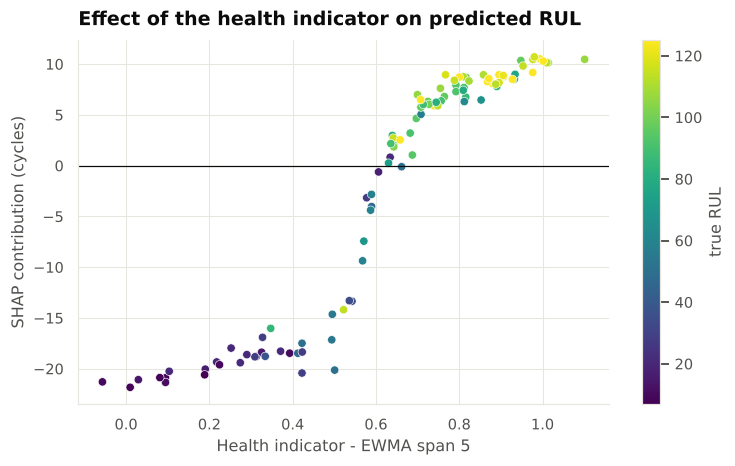

In [4]:
hi_feats = [f for f in raw_names if f.startswith("health_indicator") and "slope" not in f and "diff" not in f]
hi_name = max(hi_feats, key=lambda f: abs_mean[f])          # most important HI level feature kept by the selector
hi_idx = raw_names.index(hi_name)
print("Health-indicator feature used:", hi_name, "-", describe_feature(hi_name))
fig, ax = plt.subplots(figsize=(7, 4.4))
sc = ax.scatter(exp.data[:, hi_idx], exp.values[:, hi_idx], c=pred.loc[X_last.unit, "rul_true"], cmap="viridis", s=30, edgecolor="white", lw=0.4)
plt.colorbar(sc, ax=ax, label="true RUL")
ax.axhline(0, color=viz.INK, lw=0.8)
ax.set(xlabel=describe_feature(hi_name), ylabel="SHAP contribution (cycles)", title="Effect of the health indicator on predicted RUL")
fig.tight_layout(); viz.save_figure(fig, f"{NAME}_shap_dependence_hi", FIG); plt.show()

A smooth, monotonic, **sigmoid** response: above HI ≈ 0.8 the contribution saturates at about +10 cycles (the engine is healthy and extra margin brings nothing — the 125-cycle plateau); between 0.7 and 0.5 it drops steeply (the degradation onset); below 0.4 it saturates again at about −20 cycles, where the other features take over to resolve the last cycles. A physically plausible shape learned from data alone — a strong sanity check.

## 2. Feature importance over the life of an engine

SHAP values computed on full trajectories of the held-out validation engines, grouped by true remaining life.

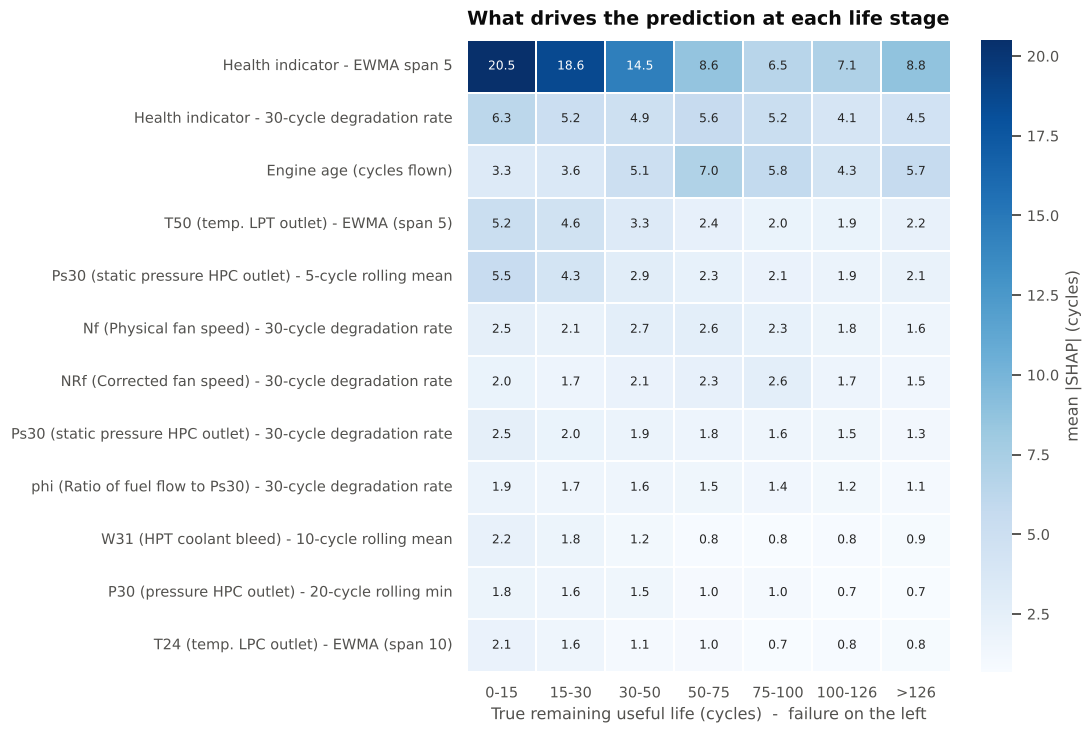

In [5]:
full = add_train_rul(ds.train, MAX_RUL)
_, val_df = split_engines(full, cfg["split"]["validation_fraction"], SEED)
F_val = bundle.compute_features(val_df.drop(columns=["rul", "rul_true"]))
F_val.index = val_df.index
sample = val_df.groupby(pd.cut(val_df["rul_true"], [-1, 15, 30, 50, 75, 100, 125, 1000]), observed=True).sample(
    90, random_state=SEED, replace=True).index.unique()
vals = explainer.shap_values(bundle.model_inputs(F_val.loc[sample]))
fig = viz.plot_shap_over_life(vals, [describe_feature(f) for f in raw_names], val_df.loc[sample, "rul_true"], top_n=12)
viz.save_figure(fig, f"{NAME}_shap_over_life", FIG); plt.show()

* **Health indicator**: its contribution triples between mid-life (≈ 6–9 cycles) and the last 15 cycles (≈ 20 cycles) — it is the main source of end-of-life precision.
* **Engine age** matters most in mid-life (50–75 cycles left, ≈ 7 cycles), when sensors have only begun to drift and the prior on typical lifetimes helps most.
* **Sensor levels** (T50, Ps30, W31, T24) become important only in the last ~30 cycles, when the drift is large compared with the noise.
* **Degradation rates** (30-cycle slopes) contribute at a fairly constant level throughout: they carry trend information at every stage.

The model "zooms in" as failure approaches, which is also why prediction intervals narrow near end of life.

## 3. Local explanation — the most critical test engine

cycle               203
rul_pred       6.129026
rul_lower      1.730218
rul_upper     13.219509
risk_level     CRITICAL
rul_true            7.0


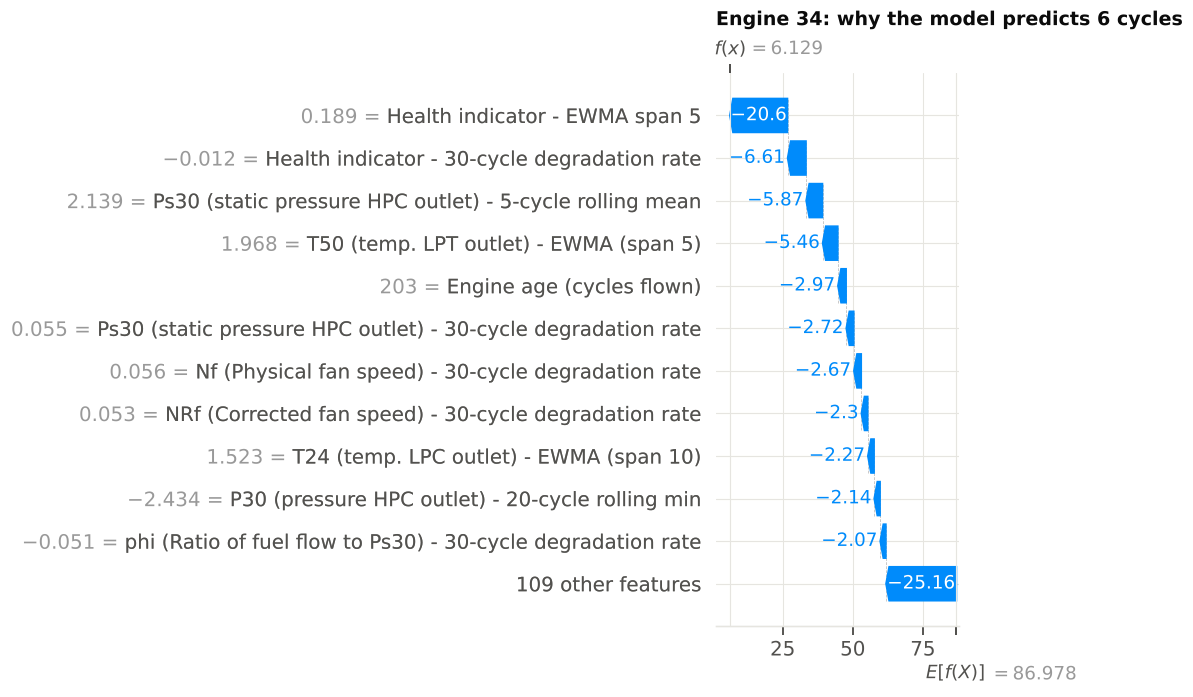

In [6]:
crit_unit = pred["rul_lower"].idxmin()
row = list(X_last.unit).index(crit_unit)
print(pred.loc[crit_unit, ["cycle", "rul_pred", "rul_lower", "rul_upper", "risk_level", "rul_true"]].to_string())
plt.figure()
shap.plots.waterfall(exp[row], max_display=12, show=False)
fig = plt.gcf(); fig.set_size_inches(10, 6.5)
plt.title(f"Engine {crit_unit}: why the model predicts {pred.loc[crit_unit, 'rul_pred']:.0f} cycles", loc="left", fontweight="bold")
plt.tight_layout(); viz.save_figure(fig, f"{NAME}_shap_waterfall_critical", FIG); plt.show()

Starting from the fleet-average prediction (87 cycles), each bar shows how much a feature moves this engine's RUL. The explanation is **actionable**: low and falling health indicator, high Ps30 and T50, all pointing to the HPC degradation signature that an engineer can confirm with a borescope inspection before removal. About a third of the total shift comes from the long tail of 109 smaller features that all point the same way — the alert is not a single-sensor artefact.

## 4. What distinguishes high-risk engines?

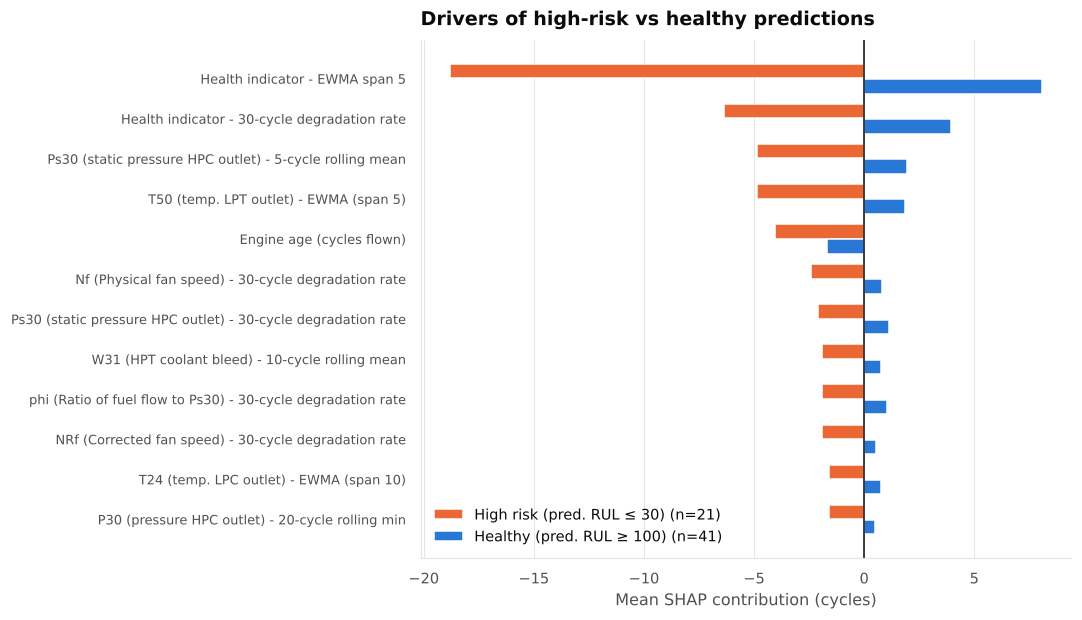

In [7]:
risk = pred.loc[X_last.unit, "rul_pred"].to_numpy()
groups = {"High risk (pred. RUL ≤ 30)": risk <= 30, "Healthy (pred. RUL ≥ 100)": risk >= 100}
mean_shap = pd.DataFrame({g: exp.values[m].mean(0) for g, m in groups.items()}, index=exp.feature_names)
top = mean_shap.abs().max(axis=1).nlargest(12).index
fig, ax = plt.subplots(figsize=(10, 5.8))
yy = np.arange(len(top))
for i, g in enumerate(groups):
    ax.barh(yy + (i - 0.5) * 0.38, mean_shap.loc[top, g], height=0.36, color=viz.PALETTE[[1, 0][i]], label=f"{g} (n={groups[g].sum()})")
ax.set_yticks(yy, top, fontsize=8.5); ax.invert_yaxis(); ax.axvline(0, color=viz.INK, lw=1)
ax.set(xlabel="Mean SHAP contribution (cycles)", title="Drivers of high-risk vs healthy predictions")
ax.legend(loc="lower left"); ax.grid(axis="y", visible=False)
fig.tight_layout(); viz.save_figure(fig, f"{NAME}_shap_risk_groups", FIG); plt.show()

The same features drive both groups — in opposite directions (the only exception is engine age, which slightly lowers the RUL of both groups). High-risk predictions are not caused by one anomalous sensor but by a **consistent, multi-sensor degradation pattern**, which makes them robust to individual sensor faults.

## 5. Inside the stacking ensemble

Meta-learner weights: {'ridge': 0.0, 'random_forest': 0.013, 'extra_trees': 0.123, 'hgb': 0.876}


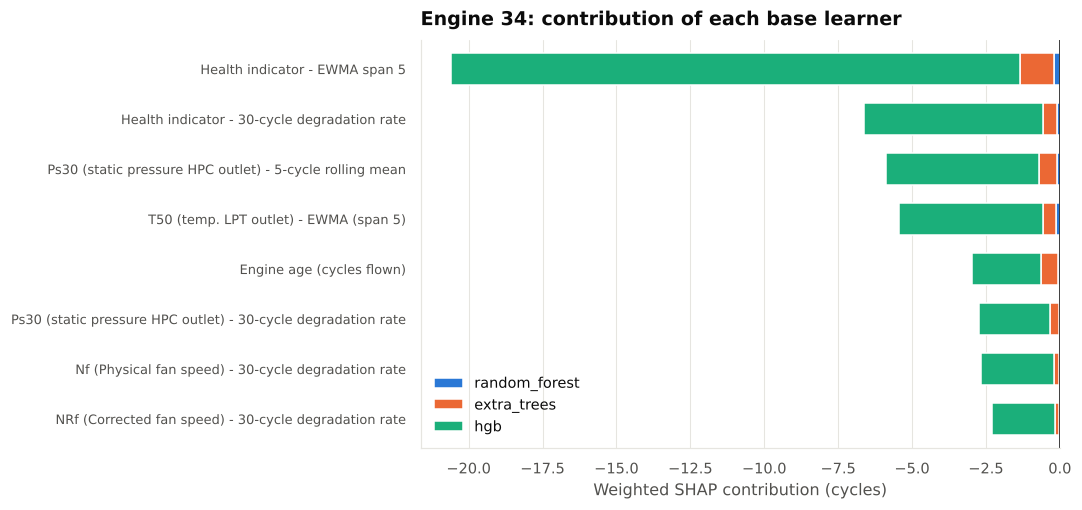

In [8]:
_, parts = explainer.shap_values(bundle.model_inputs(X_last.iloc[[row]]), per_model=True)
contrib = pd.DataFrame({m: v[0] for m, v in parts.items()}, index=[describe_feature(f) for f in raw_names])
top = contrib.sum(axis=1).abs().nlargest(8).index
weights = pd.Series(bundle.model_pipeline[-1].final_estimator_.coef_, index=list(bundle.model_pipeline[-1].named_estimators_)) \
    if hasattr(bundle.model_pipeline[-1], "final_estimator_") else pd.Series({"model": 1.0})
print("Meta-learner weights:", weights.round(3).to_dict())
ax = contrib.loc[top].plot.barh(stacked=True, figsize=(10, 4.8), color=viz.PALETTE[:contrib.shape[1]], width=0.65)
ax.invert_yaxis(); ax.axvline(0, color=viz.INK, lw=1); ax.tick_params(axis="y", labelsize=8.5)
ax.set(xlabel="Weighted SHAP contribution (cycles)", title=f"Engine {crit_unit}: contribution of each base learner"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 6. Cross-scenario comparison

Global importances (test engines) of the four production models, aggregated by feature family.

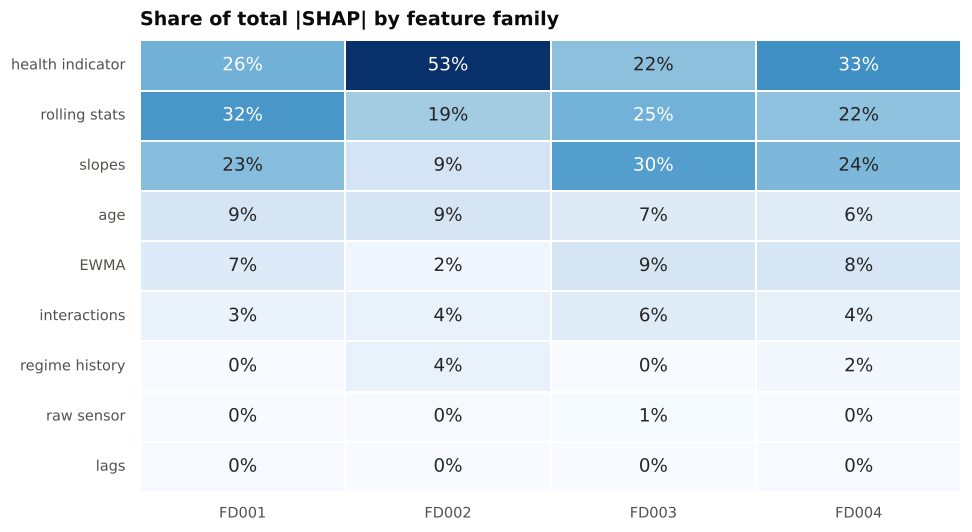

In [9]:
def fam(f):
    if f.startswith("health_indicator"): return "health indicator"
    for k, v in [("_roll", "rolling stats"), ("_ewm", "EWMA"), ("_lag", "lags"), ("_diff", "differences"),
                 ("_slope", "slopes"), ("ix_", "interactions"), ("hist_share", "regime history"), ("op_condition", "regime (current)")]:
        if k in f: return v
    return "age" if f == "cycle" else "raw sensor"
shares = {}
for d in ["FD001", "FD002", "FD003", "FD004"]:
    imp = pd.read_csv(ROOT / "data" / "processed" / f"{d}_shap_importance.csv")
    s = imp.groupby(imp.feature.map(fam))["mean_abs_shap"].sum()
    shares[d] = s / s.sum()
shares = pd.DataFrame(shares).fillna(0)
shares = shares.loc[shares.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(shares, annot=True, fmt=".0%", cmap=viz.SEQUENTIAL, linewidths=1, linecolor="white", ax=ax, cbar=False)
ax.set(title="Share of total |SHAP| by feature family", xlabel="", ylabel="")
fig.tight_layout(); viz.save_figure(fig, "shap_family_share_all", FIG); plt.show()

* Across all scenarios the model relies on the same *physically meaningful* families: health indicator, rolling statistics and degradation rates account for 77–81 % of total attribution.
* **FD002** leans most on the health indicator (53 %): fusing 14 regime-normalised sensors averages out the residual regime noise that single sensors still carry.
* **FD003** (two fault modes) leans least on it (22 %) and most on sensor-level slopes (30 %), consistent with the EDA finding that the two modes move some sensors in opposite directions — a single linear indicator cannot represent both.
* Regime-history features receive a small but non-zero share only where regimes exist (FD002 4 %, FD004 2 %).
* **Lag features receive ~0 % everywhere**: they are redundant with rolling statistics and EWMAs and could be dropped to simplify the pipeline.

## Summary for stakeholders

| Question | Answer |
|---|---|
| Can the prediction be trusted? | Contributions are additive and exact; the learned effects are monotonic and physically plausible. |
| What drives a removal alert? | A consistent multi-sensor HPC degradation pattern (Ps30, T50, fan/core speeds, phi) summarised by the health indicator and its rate of change. |
| When does the model become informative? | Degradation trends are picked up from ~100 cycles before failure; precision sharpens strongly in the last 30 cycles. |
| What should an engineer check? | The sensors with the largest negative contributions in the engine's waterfall — exposed in the Streamlit app for every engine. |